<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QSVM_QCNN_StreamIDS_Kalinin2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QSVM and QCNN for stream-based intrusion detection: Kalinin and Krundyshev (2023) step by step

This notebook re-implements, runs and checks the experiments of

> Maxim Kalinin and Vasiliy Krundyshev,
> "Security intrusion detection using quantum machine learning techniques",
> *Journal of Computer Virology and Hacking Techniques* 19, 125-136 (2023).
> https://doi.org/10.1007/s11416-022-00435-0

**What the paper does.** It proposes to classify network *streams* (a group of packets summarised by 58 statistics such as
mean/std/min/max of packet length, TTL, window size, inter-packet interval, flag averages, packet rate) instead of single
packets, encodes every stream on a qubit with one `Rx` rotation per field, and compares a **quantum SVM (QSVM)** and a **quantum
convolutional neural network (QCNN)** with a classical SVM and a classical CNN. It reports "98 % accuracy" and "twice faster
training" on a private 10-million-stream dataset.

**What this notebook does.** The paper's stream dataset is not public (it was built from the IEEE DataPort "IoT Network Intrusion Dataset"
plus the authors' own `nmap`/`hping` traffic, and is not released), so the notebook uses a public stand-in with the *same
kind of fields*: **Bot-IoT** (Koroniotis et al., 2019), whose records are already per-stream statistics (duration, packet and byte
counts, mean/std/min/max of inter-packet times, packet rates, flags, ports) and whose attack types (HTTP flood, TCP/UDP floods, port
scan, OS fingerprinting, keylogging, data exfiltration) match the attacks named in the paper's Fig. 5 (HTTP flooding, port scanning,
ACK flooding). It then
1. builds the paper's own encoding (one qubit, one `Rx(angle in [0, pi])` per field) and shows what that circuit really computes;
2. trains a **QSVM** with that literal encoding and a **QSVM with an 8-qubit ZZ feature map** (the paper does not give its Fig. 1 circuit in usable detail);
3. trains an **8-qubit QCNN** (convolution and pooling blocks after Cong, Choi and Lukin, which the paper cites) with 3 read-out qubits for 8 classes;
4. trains the classical comparison models (SVM unscaled and tuned, Random Forest, Keras 1-D CNN) on the same inputs;
5. re-draws the paper's Figs. 5-8 (per-class accuracy, confusion matrices, ROC) and its Table 4 (training time against data volume) at CPU scale;
6. prints a claim-by-claim comparison with the paper.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. No GPU, no IBM account.
`FAST_MODE = True` takes about 6 minutes; `FAST_MODE = False` is the full run (3 seeds, 500 streams per class; 1.5 to 2 hours measured on a laptop CPU: the QCNN state-vector training dominates; use FAST_MODE for a class demo).

## The paper in one page

**Problem.** Intrusion detection on "big data" (more than 10^6 records) is slow or inaccurate with classical ML; the authors want to know whether QML helps.

**Decision.** Multi-class classification of network **streams** (normal traffic and several attack types), not of single packets.

**Data (Section 5).** A "stream dataset" with **58 fields** and over **10 million records**, derived from the IEEE DataPort *IoT Network Intrusion Dataset*
(Mirai-style attacks) and extra `nmap`/`hping` traffic captured with Wireshark/`tshark`. Fields are per-stream statistics (Table 3): mean flag values, packet-length
statistics, payload statistics, port std, TTL, TCP sequence/ack numbers, window size, inter-burst interval statistics, packet count, duration, packet rate.

**Encoding (Section 6, Figs. 3-4).** One qubit per stream (`cirq.GridQubit(1,1)`). The source IP is turned into a number and then a rotation angle (`Rx`); then
for every one of the numeric fields `j = 1..58` the value is mapped to an angle in `[0, pi]` and **another `Rx` gate is appended to the same qubit**.

**Models (Sections 3 and 7).** QSVM (circuit in IBM Circuit Composer, Fig. 1, details not given) and QCNN (generic circuit model, Fig. 2, trained by minimising the mean
squared error, Eq. 13) implemented with TensorFlow Quantum / Cirq on Ubuntu with a CUDA emulator; conventional SVM and CNN as comparison. No hyper-parameters, split, optimiser or number of epochs are given.

**Claims we can test (all from figures and one table; the paper prints no accuracy table).**

| Id | Claim | Where |
|---|---|---|
| C1 | QSVM classifies the streams with an accuracy of 98 % | Fig. 6, abstract, conclusion |
| C2 | The conventional SVM detects only HTTP flooding and port scanning well; most other classes are at 0.4-0.8; ACK flooding is practically undetected | Fig. 5 |
| C3 | The QCNN detects normal traffic with 98 % accuracy (confusion matrix) | Fig. 8 |
| C4 | The QCNN has better ROC curves than the QSVM | Figs. 6 and 8 |
| C5 | The quantum models are more accurate than the conventional SVM and CNN | Figs. 5-8, conclusion |
| C6 | QSVM and QCNN train about twice as fast as SVM and CNN on big inputs, and the gap grows with the data volume | Table 4 |
| C7 | The 58-field stream dataset with over 10 M records exists | Section 5 |

Table 4 of the paper (training time in hours; the PDF text has the four columns glued together, they are separated here by hand from the layout-mode extraction):

| samples | SVM | QSVM | CNN | QCNN |
|---|---|---|---|---|
| 100,000 | 0.5 | 0.4 | 0.7 | 0.5 |
| 500,000 | 4.4 | 2.3 | 4.9 | 2.7 |
| 1,000,000 | 9.6 | 5.2 | 10.9 | 5.6 |
| 2,500,000 | 12.6 | 6.1 | 15.5 | 6.8 |
| 5,000,000 | 16.9 | 8 | 26.9 | 9.9 |
| 10,000,000 | 22.4 | 10.6 | 36.7 | 14.5 |

(The notebook stores all 13 rows. The 600,000-row QSVM entry is printed as "3" in the PDF.)

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | private stream dataset, 58 fields, > 10 M records, own `nmap`/`hping` traffic | **Bot-IoT** (public, Hugging Face mirror `masoltani/bot-iot`, first parquet row group, about 1 M records). 20 per-stream statistic fields; 8 classes. Class-balanced sample of 150 (FAST) or 500 (full) streams per class. See the table below |
| Classes | normal and several attacks (HTTP flooding, port scanning, ACK flooding, ... not listed completely) | Normal, HTTP flood, TCP flood (the closest to ACK flooding), UDP flood, Port scan (service scan), OS fingerprint, Keylogging, Data exfiltration. DoS and DDoS variants of the same protocol are merged |
| Fields | 58 (Table 3) | 20: `flgs, proto, state, sport, dport, pkts, bytes, dur, mean, stddev, sum, min, max, spkts, dpkts, sbytes, dbytes, rate, srate, drate`. Host-level counters (`TnP_*`, `N_IN_Conn_*`), `stime`, `ltime`, `seq` are dropped as identifiers/time (`# CHOICE:`) |
| Scaling | each field mapped to `[0, pi]` | `log1p` of every (non-negative) field, then MinMax to `[0, pi]` fitted on the training split; test values clipped |
| Paper encoding | one qubit, one `Rx` per field | Built and tested exactly like that ("QSVM literal"), including a proof that it collapses to one number |
| QSVM circuit | Fig. 1 (IBM Composer), not reproducible from the text | (a) literal single-qubit encoding; (b) **8-qubit `zz_feature_map(reps=2, linear)`** on 8 PCA angles, kernel `\|<phi(a)\|phi(b)>\|^2`, bandwidth and `C` chosen on a validation split of the training data (`# CHOICE:`) |
| QCNN circuit | Fig. 2, generic; TensorFlow Quantum / Cirq | 8 qubits, `Rx` data encoding, 2 convolution + 2 pooling layers with independent parameters per block, a final 3-qubit "fully connected" layer, **3 read-out qubits = 8 outcomes = 8 classes** (`# CHOICE:`); 63 trainable parameters. Qiskit circuit for drawing, an exactly equivalent PyTorch state-vector replay for fast gradients (equivalence asserted) |
| QCNN loss | mean squared error (Eq. 13) | cross-entropy on the 8 outcome probabilities (`# CHOICE:`), Adam |
| Software | Python 3.7, Cirq, TF Quantum, CUDA emulator | Qiskit 2.5.2 + qiskit-machine-learning 0.9.1, PyTorch (state-vector simulator, CPU), Keras for the classical CNN. Cirq / TF Quantum are not installable on a current Colab |
| Split, seeds | not given | stratified 70 / 30, seeds `SEEDS`, every transform fitted on the training split only |
| Classical SVM | "conventional SVM", settings not given | (a) default `SVC()` on the unscaled raw fields (what a naive run gives); (b) RBF-SVM with `C` and `gamma` tuned by 3-fold CV on the training split, on 20 standardised fields and on the same 8 angles the quantum models see |
| Classical CNN | "conventional CNN", architecture not given | Keras 1-D CNN (2 conv layers, global max-pool, dense) on the 20 standardised fields and on the 8 angles |
| Data volume | > 10^6 streams | at most about 3,000 streams (CPU state-vector simulation limit). The "big data" claim C6 can only be probed in trend |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, PyTorch and TensorFlow/Keras.
# The pip line runs on Colab (or wherever Qiskit is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" pylatexenc pyarrow huggingface_hub
print("setup done (if Colab asks you to restart the session, do so and run all cells again)")

setup done (if Colab asks you to restart the session, do so and run all cells again)


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False           # True: class demo in about 6 minutes. False: 3 seeds, 500 streams per class (1.5-2 h measured on a laptop CPU).

SEED       = 42             # master seed
SEEDS      = [42] if FAST_MODE else [42, 43, 44]
N_QUBITS   = 8              # CHOICE: 8 PCA angles = 8 qubits for the ZZ feature map and the QCNN (the paper's own encoding uses 1 qubit)
N_PER_CLASS = 150 if FAST_MODE else 500   # streams per class (paper: > 10^6 streams in total)
TEST_SIZE  = 0.3            # CHOICE: the paper gives no split

# QSVM
ZZ_REPS    = 2
BANDWIDTHS = [0.25, 0.5, 1.0] # CHOICE: angle scale of the ZZ feature map, picked on a validation split of the training data
C_GRID     = [1.0, 10.0, 100.0]

# QCNN
QCNN_EPOCHS = 40                         # CHOICE: the paper does not give epochs
QCNN_BATCH  = 128                        # (memory of the autograd graph grows with the batch: 128 needs about 0.4 GB)
QCNN_LR     = 0.05
QCNN_INIT   = 0.5                        # std of the Gaussian initial weights

# Keras CNN
CNN_EPOCHS = 20 if FAST_MODE else 40

# timing study (analogue of the paper's Table 4)
TIMING_N = [100, 200, 400, 800] if FAST_MODE else [250, 500, 1000, 2000]

DATA_DIR  = "qc017_data"    # where the downloaded sample is cached
DATA_PATH = ""              # optional: path to your own copy of the Bot-IoT parquet / csv
HF_REPO, HF_FILE = "masoltani/bot-iot", "balanced_dataset.parquet"
IBM_TOKEN = ""              # unused: the paper simulates its circuits, no hardware is needed
print("FAST_MODE =", FAST_MODE, "| seeds", SEEDS, "| streams per class", N_PER_CLASS)

FAST_MODE = False | seeds [42, 43, 44] | streams per class 500


In [3]:
import os, time, warnings, itertools
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
import sklearn, torch, qiskit, qiskit_machine_learning
import tensorflow as tf
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve)
from sklearn.preprocessing import label_binarize
from qiskit import QuantumCircuit, ClassicalRegister
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.algorithms import QSVC

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
np.random.seed(SEED); torch.manual_seed(SEED); tf.random.set_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__, "| torch", torch.__version__,
      "| tensorflow", tf.__version__, "| sklearn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

# Hugging Face token (only needed if a mirror ever becomes gated; Bot-IoT here is public). Never type a token into the notebook:
# on Colab store it in Settings > Secrets as HF_TOKEN.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | torch 2.14.1+cpu | tensorflow 2.21.0 | sklearn 1.9.1 | numpy 2.5.4 | pandas 3.0.6


## 1. The data: Bot-IoT streams as a public stand-in for the paper's stream dataset

The paper's own dataset (58 fields, over 10 million streams, partly captured with `nmap` and `hping`) is **not published**, and the public source it started from
(IEEE DataPort *IoT Network Intrusion Dataset*) contains packet captures behind a login. We therefore use **Bot-IoT** (Koroniotis, Moustafa, Sitnikova, Turnbull 2019, UNSW Canberra),
which the paper itself names in Section 5. A Bot-IoT record is a network *flow* (an Argus stream) described by per-stream statistics: duration, packet and byte counts per direction, mean, standard deviation,
minimum and maximum of the inter-packet times, packet and byte rates, the flag/state/protocol codes and the ports. That is exactly the kind of field Table 3 of the paper lists, and it needs no
packet capture. Attack families: DoS/DDoS floods over TCP, UDP and HTTP, reconnaissance (service scan = port scanning, OS fingerprinting) and theft (keylogging, data exfiltration).

We read one parquet row group (about 1 M rows, the 22 columns we need) of the Hugging Face mirror `masoltani/bot-iot`; it contains **all** records of the rare classes (normal, keylogging, data exfiltration, OS fingerprint, HTTP flood).
The file is cached in `DATA_DIR`. If the partial read fails the code falls back to downloading the whole 730 MB file.

In [4]:
FIELDS = ["flgs_number", "proto_number", "state_number", "sport", "dport", "pkts", "bytes", "dur", "mean", "stddev", "sum", "min", "max",
          "spkts", "dpkts", "sbytes", "dbytes", "rate", "srate", "drate"]          # CHOICE: 20 per-stream statistics (paper: 58)
LABELS = ["attack", "category", "subcategory"]

def load_botiot():
    # Return the Bot-IoT sample (one parquet row group) as a DataFrame, cached in DATA_DIR.
    if DATA_PATH and os.path.exists(DATA_PATH):
        return pd.read_parquet(DATA_PATH, columns=FIELDS + LABELS) if DATA_PATH.endswith(".parquet") else pd.read_csv(DATA_PATH, usecols=FIELDS + LABELS)
    cache = os.path.join(DATA_DIR, "botiot_rowgroup0.parquet")
    if os.path.exists(cache):
        return pd.read_parquet(cache)
    import pyarrow.parquet as pq
    try:
        from huggingface_hub import HfFileSystem
        fs = HfFileSystem(token=HF_TOKEN)
        with fs.open(f"datasets/{HF_REPO}/{HF_FILE}", "rb") as f:
            df = pq.ParquetFile(f).read_row_group(0, columns=FIELDS + LABELS).to_pandas()
    except Exception as e:                                       # fallback: download the whole file once
        print("partial read failed (", str(e)[:80], ") -> downloading the full file")
        from huggingface_hub import hf_hub_download
        p = hf_hub_download(HF_REPO, HF_FILE, repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN)
        df = pq.ParquetFile(p).read_row_group(0, columns=FIELDS + LABELS).to_pandas()
    for c in ("category", "subcategory"):
        df[c] = df[c].astype(str)
    df.to_parquet(cache)
    return df

t0 = time.time()
raw = load_botiot()
for c in ("category", "subcategory"):
    raw[c] = raw[c].astype(str)
print("loaded", raw.shape, "in %.0f s" % (time.time() - t0))

loaded (1048576, 23) in 1 s


### Cleaning and class labels

Following the repository's recipe: coerce to numeric, replace +-inf by NaN and drop, drop duplicate rows (Bot-IoT has many repeated flows) and constant columns. Then the Bot-IoT `subcategory` is grouped
into **8 classes** whose names follow the paper's attack names (the paper's "ACK flooding" is the closest to the TCP flood here). We keep the class index of each name in a fixed order.

In [5]:
CLASS_OF = {"Normal": "Normal", "D-H": "HTTP flood", "DD-H": "HTTP flood", "D-T": "TCP flood", "DD-T": "TCP flood", "D-U": "UDP flood", "DD-U": "UDP flood",
            "Service_Scan": "Port scan", "OS_Fingerprint": "OS fingerprint", "Keylogging": "Keylogging", "Data_Exfiltration": "Data exfiltration"}
CLASSES = ["Normal", "HTTP flood", "TCP flood", "UDP flood", "Port scan", "OS fingerprint", "Keylogging", "Data exfiltration"]
K = len(CLASSES)

n0 = len(raw)
df = raw.copy()
df[FIELDS] = df[FIELDS].apply(pd.to_numeric, errors="coerce")
df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=FIELDS)
df = df.drop_duplicates()
const = [c for c in FIELDS if df[c].nunique() <= 1]
df = df.drop(columns=const)
FIELDS = [c for c in FIELDS if c not in const]
df["cls"] = df["subcategory"].map(CLASS_OF)
df = df.dropna(subset=["cls"]).reset_index(drop=True)
df["y"] = df["cls"].map({c: i for i, c in enumerate(CLASSES)})
print(f"rows {n0} -> {len(df)} after cleaning; constant columns dropped: {const}; fields kept: {len(FIELDS)}")
print((df[FIELDS] < 0).sum().sum(), "negative field values (log1p below is applied after clipping at 0)")
F = len(FIELDS)

rows 1048576 -> 968265 after cleaning; constant columns dropped: []; fields kept: 20
1066 negative field values (log1p below is applied after clipping at 0)


In [6]:
def draw_split(seed, n_per_class=None):
    # Class-balanced sample + stratified 70/30 split (reproducible per seed).
    n_per_class = n_per_class or N_PER_CLASS
    parts = [g.sample(min(len(g), n_per_class), random_state=seed) for _, g in df.groupby("cls")]
    d = pd.concat(parts).reset_index(drop=True)
    X = d[FIELDS].to_numpy(float); y = d["y"].to_numpy(int)
    return train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=seed)

class Prep:
    # Every transform is fitted on the training split only.
    def __init__(self, seed):
        self.seed = seed
    @staticmethod
    def logt(X): return np.log1p(np.clip(X, 0, None))
    def fit(self, Xtr):
        L = self.logt(Xtr)
        self.sc = StandardScaler().fit(L)
        self.pca = PCA(n_components=N_QUBITS, random_state=self.seed).fit(self.sc.transform(L))
        self.mm = MinMaxScaler((0, np.pi)).fit(self.pca.transform(self.sc.transform(L)))   # PCA coordinates -> angles for the 8-qubit models
        self.mm_all = MinMaxScaler((0, np.pi)).fit(L)                                       # every field -> angle (paper's one-qubit encoding)
        return self
    def std(self, X): return self.sc.transform(self.logt(X))                                # standardised log fields (classical models)
    def pca_raw(self, X): return self.pca.transform(self.std(X))
    def angles(self, X): return np.clip(self.mm.transform(self.pca_raw(X)), 0, np.pi)      # N_QUBITS angles in [0, pi]
    def fields_angles(self, X): return np.clip(self.mm_all.transform(self.logt(X)), 0, np.pi)  # F angles in [0, pi]

SPLIT = {}
for s in SEEDS:
    Xtr, Xte, ytr, yte = draw_split(s)
    P = Prep(s).fit(Xtr)
    SPLIT[s] = dict(Xtr=Xtr, Xte=Xte, ytr=ytr, yte=yte, P=P, Atr=P.angles(Xtr), Ate=P.angles(Xte), Str=P.std(Xtr), Ste=P.std(Xte),
                    Ftr=P.fields_angles(Xtr), Fte=P.fields_angles(Xte))
s0 = SEEDS[0]
print({k: v.shape for k, v in SPLIT[s0].items() if hasattr(v, "shape")})

{'Xtr': (2800, 20), 'Xte': (1200, 20), 'ytr': (2800,), 'yte': (1200,), 'Atr': (2800, 8), 'Ate': (1200, 8), 'Str': (2800, 20), 'Ste': (1200, 20), 'Ftr': (2800, 20), 'Fte': (1200, 20)}


## Dataset Exploration and Visualisation

Everything below shows the **real Bot-IoT streams** and their ground-truth labels. First the shape, the field names and the original label values (Bot-IoT's own `attack`, `category` and `subcategory`), then the class distribution,
then 2-D scatter plots of the real training streams: the first two PCA coordinates of the standardised log-fields (fitted on the training split), and the same points after the MinMax scaling to angles in `[0, pi]` that the 8-qubit models use.

In [7]:
print("shape after cleaning (rows, columns):", df.shape)
print("stream fields (%d):" % F, FIELDS)
print("\noriginal Bot-IoT labels")
print("  attack      :", raw["attack"].value_counts().to_dict())
print("  category    :", raw["category"].value_counts().to_dict())
print("  subcategory :", raw["subcategory"].value_counts().to_dict())
print("\ncleaned pool, 8 classes:")
print(df["cls"].value_counts().reindex(CLASSES))
print("\nsample used for seed %d: train %d / test %d streams" % (s0, len(SPLIT[s0]["ytr"]), len(SPLIT[s0]["yte"])))
display(df[FIELDS + ["subcategory", "cls"]].head(5))
display(df[FIELDS].describe().T[["mean", "std", "min", "max"]])

shape after cleaning (rows, columns): (968265, 25)
stream fields (20): ['flgs_number', 'proto_number', 'state_number', 'sport', 'dport', 'pkts', 'bytes', 'dur', 'mean', 'stddev', 'sum', 'min', 'max', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'srate', 'drate']

original Bot-IoT labels
  attack      : {1: 1043684, 0: 4892}
  category    : {'DDoS': 542232, 'DoS': 465885, 'Reconnaissance': 25580, 'Theft': 9987, 'Normal': 4892}
  subcategory : {'D-U': 288410, 'DD-T': 273118, 'DD-U': 264238, 'D-T': 172499, 'Service_Scan': 20604, 'Data_Exfiltration': 5029, 'OS_Fingerprint': 4976, 'D-H': 4976, 'Keylogging': 4958, 'Normal': 4892, 'DD-H': 4876}

cleaned pool, 8 classes:


cls
Normal                 4068
HTTP flood             8834
TCP flood            410618
UDP flood            514304
Port scan             18047
OS fingerprint         4619
Keylogging             3885
Data exfiltration      3890
Name: count, dtype: int64

sample used for seed 42: train 2800 / test 1200 streams


,flgs_number,proto_number,state_number,sport,dport,pkts,bytes,dur,mean,stddev,sum,min,max,spkts,dpkts,sbytes,dbytes,rate,srate,drate,subcategory,cls
0,1,1,1,16312,80,12,1284,46.044857,0.128858,0.129378,0.773150,0.000000,0.279299,9,3,1104,180,0.238897,0.173744,0.083536,DD-T,TCP flood
1,1,1,1,16347,80,4,428,9.467592,0.055318,0.055318,0.110636,0.000000,0.110636,3,1,368,60,0.316870,0.211247,0.000000,DD-T,TCP flood
2,1,3,4,63139,80,8,480,31.612387,2.077319,1.699977,10.386595,0.000000,3.670143,8,0,480,0,0.221432,0.221432,0.000000,D-U,UDP flood
3,1,1,1,54776,161,2,120,0.001119,0.001119,0.000000,0.001119,0.001119,0.001119,1,1,60,60,893.655029,0.000000,0.000000,Service_Scan,Port scan
4,1,3,4,48855,80,10,600,25.712828,2.531211,1.536992,12.656055,0.000000,4.851535,10,0,600,0,0.350020,0.350020,0.000000,D-U,UDP flood


,mean,std,min,max
flgs_number,1.482889,0.860054,1.0,8.000000e+00
proto_number,2.081530,0.998242,1.0,5.000000e+00
state_number,3.117547,1.214927,1.0,1.100000e+01
sport,33094.020537,19047.765369,-1.0,6.553500e+04
dport,372.092717,3109.996813,-1.0,6.553500e+04
pkts,16.299144,580.020663,1.0,7.005700e+04
bytes,7962.328267,557659.827075,60.0,7.183334e+07
dur,21.607719,45.025237,0.0,2.771485e+03
mean,2.215069,1.519046,0.0,4.981882e+00
stddev,0.878871,0.803770,0.0,2.496758e+00


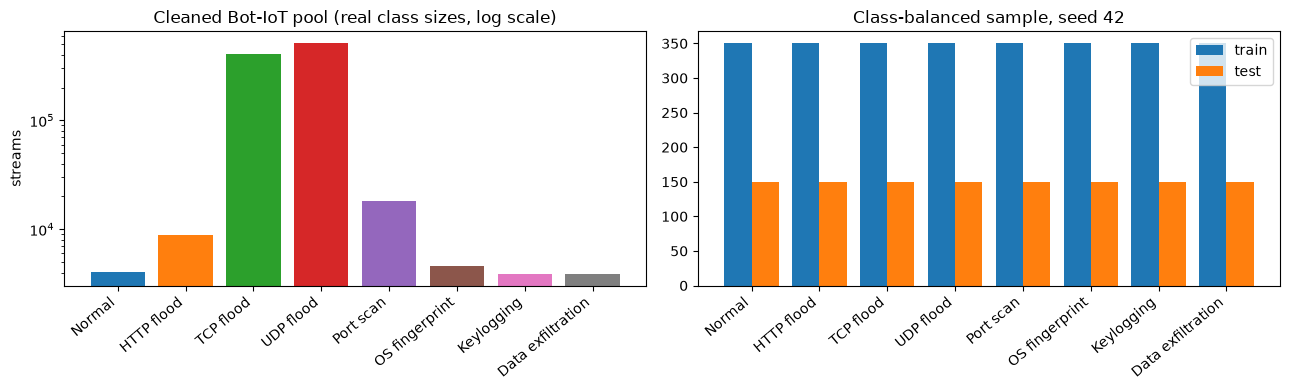

In [8]:
PAL = plt.cm.tab10(np.arange(K))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
vc = df["cls"].value_counts().reindex(CLASSES)
ax[0].bar(range(K), vc.values, color=PAL); ax[0].set_yscale("log"); ax[0].set_xticks(range(K)); ax[0].set_xticklabels(CLASSES, rotation=40, ha="right")
ax[0].set_title("Cleaned Bot-IoT pool (real class sizes, log scale)"); ax[0].set_ylabel("streams")
yb = np.bincount(SPLIT[s0]["ytr"], minlength=K); ye = np.bincount(SPLIT[s0]["yte"], minlength=K)
ax[1].bar(np.arange(K) - 0.2, yb, 0.4, label="train", color="tab:blue"); ax[1].bar(np.arange(K) + 0.2, ye, 0.4, label="test", color="tab:orange")
ax[1].set_xticks(range(K)); ax[1].set_xticklabels(CLASSES, rotation=40, ha="right"); ax[1].legend(); ax[1].set_title("Class-balanced sample, seed %d" % s0)
plt.tight_layout(); plt.show()

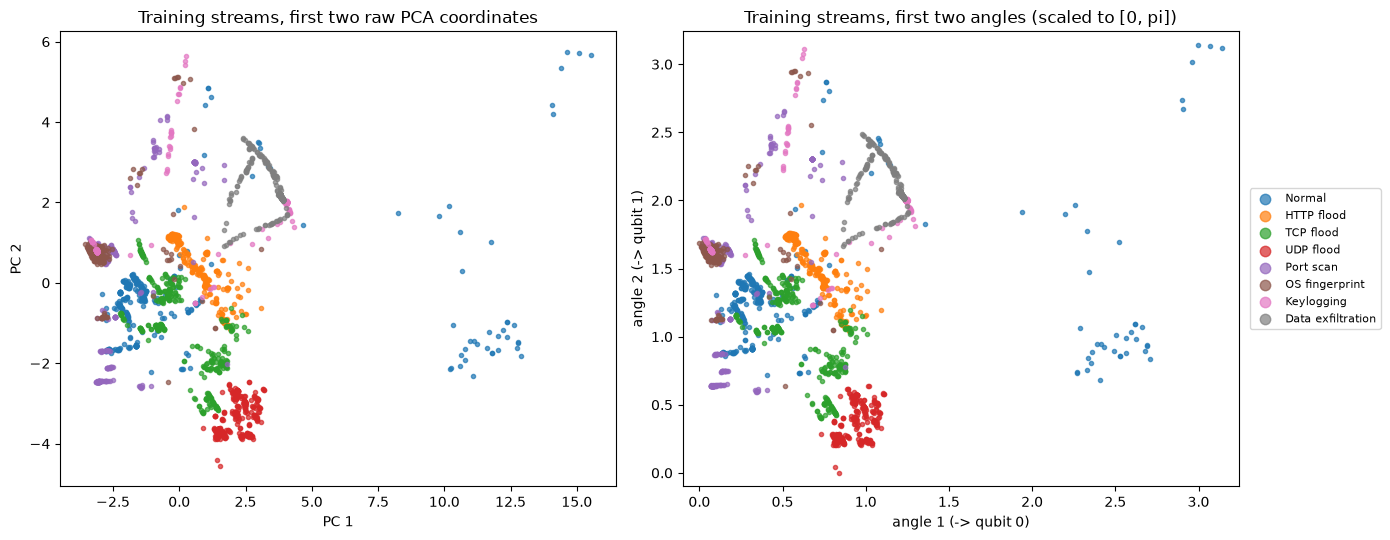

explained variance of the 8 PCA components: [0.406 0.181 0.084 0.069 0.058 0.051 0.046 0.033] cumulative 0.926


In [9]:
sp = SPLIT[s0]; ytr0 = sp["ytr"]
Z = sp["P"].pca_raw(sp["Xtr"])          # raw PCA coordinates, PCA fitted on the training split
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for k in range(K):
    m = ytr0 == k
    ax[0].scatter(Z[m, 0], Z[m, 1], s=9, alpha=0.7, color=PAL[k], label=CLASSES[k])
    ax[1].scatter(sp["Atr"][m, 0], sp["Atr"][m, 1], s=9, alpha=0.7, color=PAL[k], label=CLASSES[k])
ax[0].set_title("Training streams, first two raw PCA coordinates"); ax[0].set_xlabel("PC 1"); ax[0].set_ylabel("PC 2")
ax[1].set_title("Training streams, first two angles (scaled to [0, pi])"); ax[1].set_xlabel("angle 1 (-> qubit 0)"); ax[1].set_ylabel("angle 2 (-> qubit 1)")
ax[1].set_xlim(-0.1, np.pi + 0.1); ax[1].set_ylim(-0.1, np.pi + 0.1)
ax[1].legend(markerscale=2.5, fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout(); plt.show()
print("explained variance of the 8 PCA components:", np.round(sp["P"].pca.explained_variance_ratio_, 3), "cumulative %.3f" % sp["P"].pca.explained_variance_ratio_.sum())

## 2. The paper's encoding: one qubit, one `Rx` per field

Section 6 builds, **for every stream, a one-qubit circuit** and appends `Rx(angle_j)` for field `j = 1..58` (after the IP address rotation). The fields are mapped to angles in `[0, pi]`.
Rotations about the same axis commute and add: `Rx(a) Rx(b) = Rx(a + b)`. So the whole circuit equals a **single** rotation `Rx(S)` with `S = sum_j angle_j`, and the encoded state is
`cos(S/2)|0> - i sin(S/2)|1>`. Two streams can only be told apart by `S mod 2*pi`; the 58 (here 20) fields are collapsed into one number before any learning happens.
The fidelity kernel between two streams is then `cos^2((S_a - S_b)/2)`. We implement the encoding exactly as described and assert this identity on real streams in the circuit section below; Section 5 shows what the collapse costs in accuracy.

## Quantum Circuit Architecture

Three gate-based quantum models are trained and evaluated. Each is drawn below from the circuit object that is actually simulated, with its qubit count, depth and parameter count.

1. **Paper-literal encoding (QSVM literal):** 1 qubit, `F` `Rx` gates (data angles), no trainable parameters; the QSVM kernel is the state overlap.
2. **QSVM with an 8-qubit ZZ feature map:** `zz_feature_map(8, reps=2, entanglement="linear")`, 8 data angles, no trainable parameters; kernel = state fidelity (simulated exactly with state vectors, i.e. infinite shots).
3. **QCNN:** `Rx` encoding of the 8 PCA angles, then convolution blocks (C1: 8 blocks on a ring), pooling (P1: 4 blocks, qubits 0-3 into 4-7), convolution (C2: 4 blocks), pooling (P2: 1 block, qubit 4 into 5), a "fully connected" layer on the 3 surviving qubits 5, 6, 7 (Ry, Rz, a CNOT ring, Ry, Rz),
   and a computational-basis measurement of qubits 5, 6, 7: the 3-bit outcome is the predicted class (8 outcomes = 8 classes). The convolution / pooling blocks are the two-qubit unitaries of the Qiskit QCNN tutorial (Cong, Choi and Lukin).

Assumptions where the paper omits circuit details: the QSVM circuit of Fig. 1 and the QCNN layout of Fig. 2 are drawings without gate lists, the class read-out and the number of layers are not given, and the paper uses Cirq / TensorFlow Quantum; we use Qiskit gates with the same unitaries.

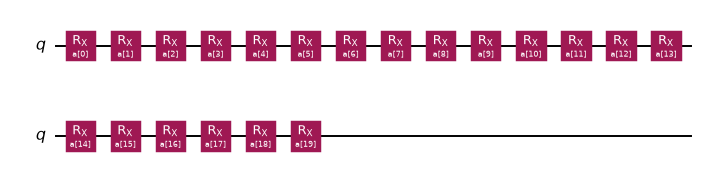

[literal] qubits: 1 | depth: 20 | trainable parameters: 0 | data angles: 20
assertion passed: the 20-gate circuit has fidelity kernel cos^2((S_a - S_b)/2) with S = sum of the 20 angles (all fields collapse into one number)


In [10]:
# ---------- (1) paper-literal encoding: ONE qubit, one Rx per field ----------
th = ParameterVector("a", F)
lit = QuantumCircuit(1)
for j in range(F):
    lit.rx(th[j], 0)
display(lit.draw("mpl", fold=14, scale=0.7))
print("[literal] qubits:", lit.num_qubits, "| depth:", lit.depth(), "| trainable parameters: 0 | data angles:", F)

def literal_states(Fa):
    # State of the literal circuit for every row of Fa (angles), computed with Qiskit's Statevector.
    return np.array([Statevector(lit.assign_parameters(dict(zip(th, a)))).data for a in Fa])
def literal_kernel_closed(Fa, Fb):
    S1 = Fa.sum(1)[:, None]; S2 = Fb.sum(1)[None, :]
    return np.cos((S1 - S2) / 2) ** 2

Fchk = SPLIT[s0]["Ftr"][:12]
PS = literal_states(Fchk)
assert np.allclose(np.abs(PS.conj() @ PS.T) ** 2, literal_kernel_closed(Fchk, Fchk), atol=1e-10)
print("assertion passed: the %d-gate circuit has fidelity kernel cos^2((S_a - S_b)/2) with S = sum of the %d angles (all fields collapse into one number)" % (F, F))

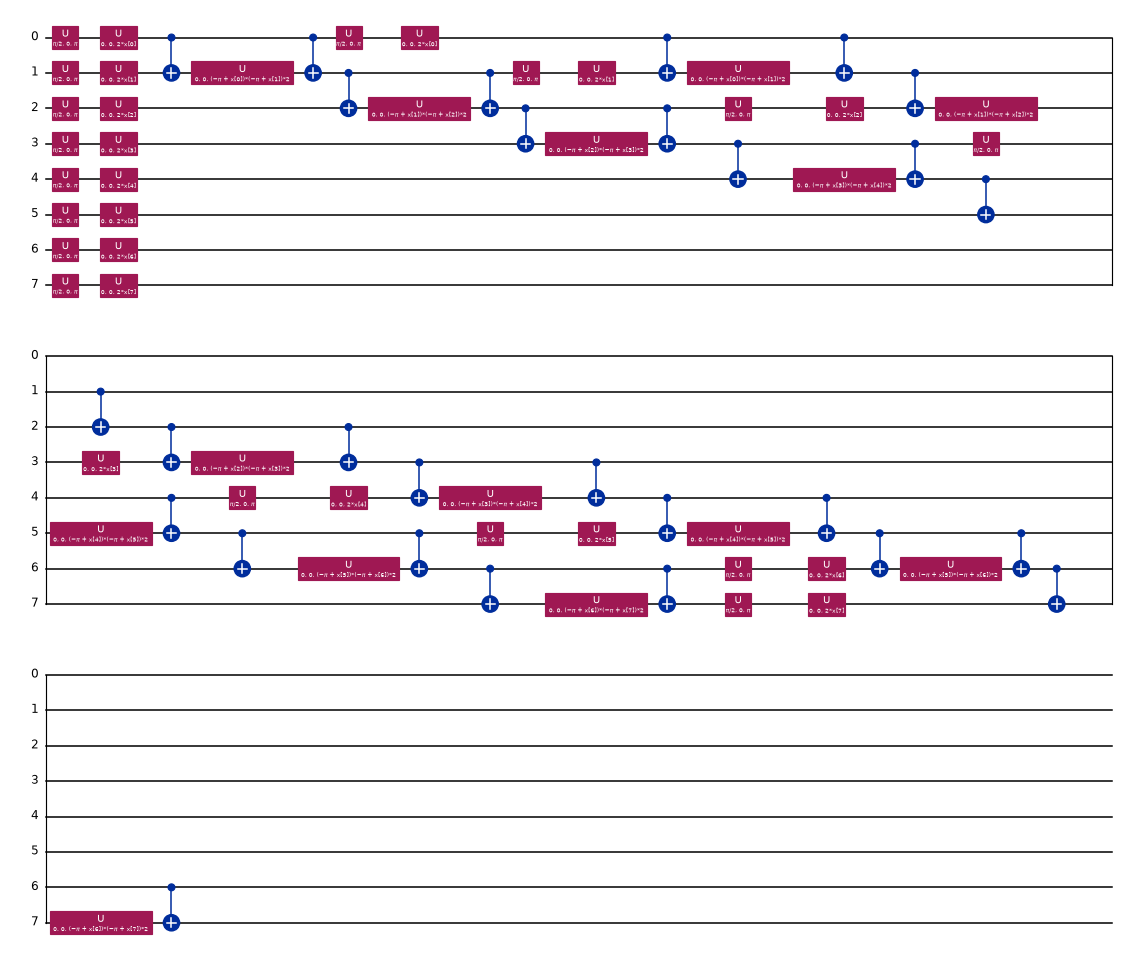

[ZZ feature map] qubits: 8 | depth (decomposed): 31 | ops: {'u': 46, 'cx': 28} | trainable parameters: 0 | data angles: 8
[ZZ kernel circuit U(x) U(y)^+ with measurement] depth: 63 | qubits: 8


In [11]:
# ---------- (2) 8-qubit ZZ feature map (QSVM) ----------
fm = zz_feature_map(N_QUBITS, reps=ZZ_REPS, entanglement="linear")
display(fm.decompose().draw("mpl", fold=30, scale=0.55))
print("[ZZ feature map] qubits:", fm.num_qubits, "| depth (decomposed):", fm.decompose().depth(), "| ops:", dict(fm.decompose().count_ops()), "| trainable parameters: 0 | data angles:", fm.num_parameters)

# the kernel circuit that a quantum computer would run for one pair: U(x) then U(y)^dagger, measure all qubits, p(0...0) = fidelity
kx = ParameterVector("x", N_QUBITS); ky = ParameterVector("y", N_QUBITS)
kc = QuantumCircuit(N_QUBITS)
kc.compose(fm.assign_parameters(list(kx)), inplace=True); kc.compose(fm.assign_parameters(list(ky)).inverse(), inplace=True); kc.measure_all()
print("[ZZ kernel circuit U(x) U(y)^+ with measurement] depth:", kc.decompose().depth(), "| qubits:", kc.num_qubits)

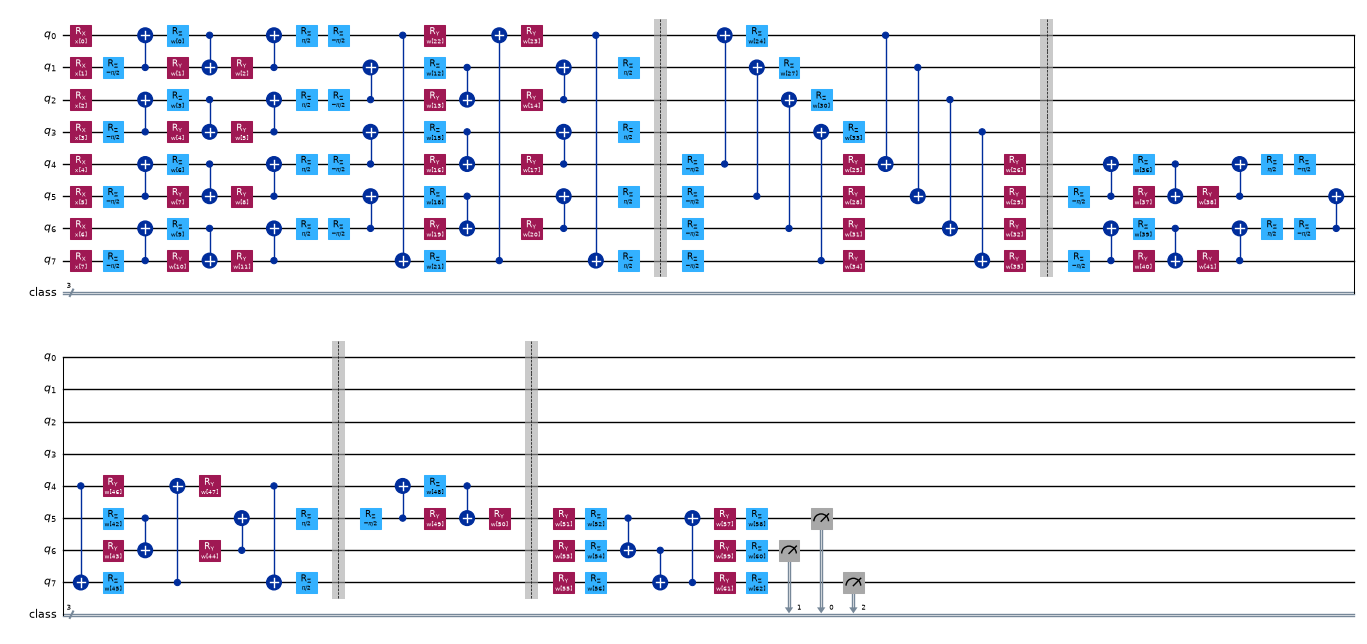

[QCNN] qubits: 8 | depth: 46 | gates: {'rz': 52, 'cx': 49, 'ry': 40, 'rx': 8, 'barrier': 4} | trainable parameters: 63 | data angles: 8 | read-out qubits: 5,6,7 -> 8 classes


In [12]:
# ---------- (3) QCNN, 8 qubits, 3 read-out qubits ----------
_cnt = [0]; _pv = ParameterVector("w", 80)
def _newp(k=3):
    p = [_pv[_cnt[0] + i] for i in range(k)]; _cnt[0] += k; return p
def conv_block(qc, a, b):
    p = _newp(); qc.rz(-np.pi / 2, b); qc.cx(b, a); qc.rz(p[0], a); qc.ry(p[1], b); qc.cx(a, b); qc.ry(p[2], b); qc.cx(b, a); qc.rz(np.pi / 2, a)
def pool_block(qc, a, b):
    p = _newp(); qc.rz(-np.pi / 2, b); qc.cx(b, a); qc.rz(p[0], a); qc.ry(p[1], b); qc.cx(a, b); qc.ry(p[2], b)
net = QuantumCircuit(8)
for a, b in [(0, 1), (2, 3), (4, 5), (6, 7), (1, 2), (3, 4), (5, 6), (7, 0)]: conv_block(net, a, b)      # C1
net.barrier()
for a, b in [(0, 4), (1, 5), (2, 6), (3, 7)]: pool_block(net, a, b)                                         # P1: 8 -> 4 active qubits (4..7)
net.barrier()
for a, b in [(4, 5), (6, 7), (5, 6), (7, 4)]: conv_block(net, a, b)                                         # C2
net.barrier()
pool_block(net, 4, 5)                                                                                       # P2: 4 -> 3 active qubits (5, 6, 7)
net.barrier()
for q in (5, 6, 7):                                                                                         # F: fully connected layer on the 3 read-out qubits
    p = _newp(2); net.ry(p[0], q); net.rz(p[1], q)
net.cx(5, 6); net.cx(6, 7); net.cx(7, 5)
for q in (5, 6, 7):
    p = _newp(2); net.ry(p[0], q); net.rz(p[1], q)
NPAR = _cnt[0]; WP = list(_pv)[:NPAR]
xs = ParameterVector("x", 8)
enc = QuantumCircuit(8)
for i in range(8): enc.rx(xs[i], i)                                  # data encoding: Rx(angle in [0, pi]) on qubit i (as in the paper, but one qubit per field)
QFULL = enc.compose(net)                                             # THE circuit that is simulated
QDRAW = QFULL.copy(); creg = ClassicalRegister(3, "class"); QDRAW.add_register(creg)
QDRAW.measure([5, 6, 7], creg)                                       # read-out of the class (drawing)
display(QDRAW.draw("mpl", fold=40, scale=0.5))
print("[QCNN] qubits:", QFULL.num_qubits, "| depth:", QFULL.depth(), "| gates:", dict(QFULL.count_ops()), "| trainable parameters:", NPAR, "| data angles: 8 | read-out qubits: 5,6,7 -> 8 classes")

In [13]:
# ---- PyTorch replay of the QCNN gate list (exact state-vector simulation with autograd) ----
idx256 = np.arange(256); pidx = {p: i for i, p in enumerate(WP)}; GATES = []
for ins in net.data:
    nm = ins.operation.name; qs = [net.find_bit(q).index for q in ins.qubits]
    if nm == "barrier": continue
    if nm == "cx":
        c, t = qs; perm = idx256.copy(); m = ((idx256 >> c) & 1) == 1; perm[m] = idx256[m] ^ (1 << t); GATES.append(("cx", torch.tensor(perm), None, None))
    else:
        a = ins.operation.params[0]
        if hasattr(a, "parameters") and len(a.parameters) > 0: GATES.append((nm, qs[0], pidx[list(a.parameters)[0]], None))
        else: GATES.append((nm, qs[0], None, float(a)))

def _mat(nm, ang):
    ang = ang if torch.is_tensor(ang) else torch.tensor(ang, dtype=torch.float64)
    c, s = torch.cos(ang / 2), torch.sin(ang / 2)
    if nm == "ry":
        return torch.stack([torch.stack([c, -s]), torch.stack([s, c])]).to(torch.complex128)
    e = torch.exp(-1j * ang / 2); z = torch.zeros_like(e)                                   # rz
    return torch.stack([torch.stack([e, z]), torch.stack([z, torch.conj(e)])])

def product_states(X):
    # Rx(x_q)|0> = cos(x/2)|0> - i sin(x/2)|1> on every qubit; qubit 0 = least significant bit (Qiskit order)
    X = torch.as_tensor(X, dtype=torch.float64); psi = torch.ones((len(X), 1), dtype=torch.complex128)
    for q in range(7, -1, -1):
        two = torch.stack([torch.cos(X[:, q] / 2).to(torch.complex128), (-1j * torch.sin(X[:, q] / 2)).to(torch.complex128)], 1)
        psi = (psi[:, :, None] * two[:, None, :]).reshape(len(X), -1)
    return psi

def qcnn_probs(psi0, theta):
    # Class probabilities = measurement distribution of qubits 5, 6, 7 (outcome index = b5 + 2 b6 + 4 b7).
    st = psi0; n = len(st)
    for nm, a, pi_, const in GATES:
        if nm == "cx": st = st[:, a]
        else:
            G = _mat(nm, theta[pi_] if pi_ is not None else const)
            st = torch.einsum("ij,bpjq->bpiq", G, st.reshape(n, 2 ** (7 - a), 2, 2 ** a)).reshape(n, 256)
    return (st.abs() ** 2).reshape(n, 8, 32).sum(2)

# equivalence of the fast replay with Qiskit's Statevector of the drawn circuit
_r = np.random.default_rng(7); th_t = _r.normal(size=NPAR); x_t = _r.uniform(0, np.pi, (4, 8))
mine = qcnn_probs(product_states(x_t), torch.tensor(th_t)).numpy()
for k in range(4):
    sv = Statevector(QFULL.assign_parameters({**dict(zip(WP, th_t)), **dict(zip(xs, x_t[k]))}))
    assert np.allclose(sv.probabilities([5, 6, 7]), mine[k], atol=1e-9)
print("assertion passed: the PyTorch replay equals Qiskit's Statevector of the drawn QCNN circuit on 4 random streams (max |diff| < 1e-9)")

assertion passed: the PyTorch replay equals Qiskit's Statevector of the drawn QCNN circuit on 4 random streams (max |diff| < 1e-9)


## 3. Classical models

Everything is trained on the same stratified split. The paper compares against a "conventional SVM" and a "conventional CNN" without giving settings, so several versions are run:

* **SVM raw**: default `SVC()` on the *unscaled* fields. This is what a naive run of an SVM on heavy-tailed network statistics gives, and the most plausible reading of the poor SVM result in the paper's Fig. 5.
* **SVM tuned**: RBF-SVM, `C` and `gamma` chosen by 3-fold cross-validation on the training split, on the 20 standardised log-fields and on the 8 angles that the quantum models see.
* **Random Forest** on both inputs.
* **CNN**: a small Keras 1-D CNN (two `Conv1D` layers, global max-pool, dense) on both inputs.

All metrics are computed on the held-out test split. Per-class recall is the paper's "accuracy of a class".

In [14]:
RES = {s: {} for s in SEEDS}         # RES[seed][model] = dict(pred, score, t_fit, t_pred)

def record(seed, name, pred, score, t_fit, t_pred, extra=None):
    RES[seed][name] = dict(pred=np.asarray(pred), score=np.asarray(score), t_fit=t_fit, t_pred=t_pred, **(extra or {}))

def keras_cnn(n_in, seed):
    tf.keras.utils.set_random_seed(seed)
    m = tf.keras.Sequential([tf.keras.layers.Input((n_in, 1)),
                             tf.keras.layers.Conv1D(16, 3, padding="same", activation="relu"),
                             tf.keras.layers.Conv1D(32, 3, padding="same", activation="relu"),
                             tf.keras.layers.GlobalMaxPooling1D(),
                             tf.keras.layers.Dense(32, activation="relu"),
                             tf.keras.layers.Dense(K, activation="softmax")])
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-2), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def fit_cnn(Atr, ytr, Ate, seed, epochs=None):
    m = keras_cnn(Atr.shape[1], seed)
    t = time.time(); m.fit(Atr[..., None], ytr, epochs=epochs or CNN_EPOCHS, batch_size=64, verbose=0); tf_ = time.time() - t
    t = time.time(); pr = m.predict(Ate[..., None], verbose=0); tp = time.time() - t
    return pr.argmax(1), pr, tf_, tp

grid = {"C": [1, 10, 100], "gamma": ["scale", 0.1, 1.0]}
for s in SEEDS:
    d = SPLIT[s]
    # SVM raw (unscaled fields, default settings)
    t = time.time(); m = SVC(decision_function_shape="ovr").fit(d["Xtr"], d["ytr"]); tf_ = time.time() - t
    t = time.time(); pr = m.predict(d["Xte"]); sc_ = m.decision_function(d["Xte"]); tp = time.time() - t
    record(s, "SVM raw fields (default)", pr, sc_, tf_, tp)
    # tuned SVM, Random Forest, CNN on the standardised fields (F inputs) and on the 8 angles
    for tag, (Tr, Te) in {"20 fields": (d["Str"], d["Ste"]), "8 angles": (d["Atr"], d["Ate"])}.items():
        t = time.time(); gs = GridSearchCV(SVC(), grid, cv=3, n_jobs=1).fit(Tr, d["ytr"]); tf_ = time.time() - t
        t = time.time(); pr = gs.predict(Te); sc_ = gs.decision_function(Te); tp = time.time() - t
        record(s, f"SVM-RBF tuned ({tag})", pr, sc_, tf_, tp, dict(best=gs.best_params_))
        rf = RandomForestClassifier(300, random_state=s, n_jobs=-1)
        t = time.time(); rf.fit(Tr, d["ytr"]); tf_ = time.time() - t
        t = time.time(); sc_ = rf.predict_proba(Te); tp = time.time() - t
        record(s, f"Random Forest ({tag})", sc_.argmax(1), sc_, tf_, tp)
        pr, sc_, tf_, tp = fit_cnn(Tr, d["ytr"], Te, s)
        record(s, f"CNN Keras ({tag})", pr, sc_, tf_, tp)
    print("seed", s, "classical done:", {k: round(float(accuracy_score(d["yte"], v["pred"])), 3) for k, v in RES[s].items()})

seed 42 classical done: {'SVM raw fields (default)': 0.191, 'SVM-RBF tuned (20 fields)': 0.939, 'Random Forest (20 fields)': 0.947, 'CNN Keras (20 fields)': 0.929, 'SVM-RBF tuned (8 angles)': 0.937, 'Random Forest (8 angles)': 0.935, 'CNN Keras (8 angles)': 0.897}


seed 43 classical done: {'SVM raw fields (default)': 0.186, 'SVM-RBF tuned (20 fields)': 0.953, 'Random Forest (20 fields)': 0.967, 'CNN Keras (20 fields)': 0.938, 'SVM-RBF tuned (8 angles)': 0.948, 'Random Forest (8 angles)': 0.953, 'CNN Keras (8 angles)': 0.907}


seed 44 classical done: {'SVM raw fields (default)': 0.198, 'SVM-RBF tuned (20 fields)': 0.945, 'Random Forest (20 fields)': 0.958, 'CNN Keras (20 fields)': 0.926, 'SVM-RBF tuned (8 angles)': 0.942, 'Random Forest (8 angles)': 0.928, 'CNN Keras (8 angles)': 0.873}


## 4. QSVM with the paper's literal one-qubit encoding

The kernel is `cos^2((S_a - S_b)/2)` with `S` the sum of the field angles (verified against Qiskit's `Statevector` above). The SVM uses `SVC(kernel="precomputed")`, `C` picked on a validation split of the training data.

In [15]:
def pick_C_precomputed(K_tr, ytr, seed):
    # Choose C on an inner validation split of the training data only.
    idx = np.arange(len(ytr)); itr, iva = train_test_split(idx, test_size=0.25, stratify=ytr, random_state=seed)
    best = max(C_GRID, key=lambda C: SVC(kernel="precomputed", C=C).fit(K_tr[np.ix_(itr, itr)], ytr[itr]).score(K_tr[np.ix_(iva, itr)], ytr[iva]))
    return best

for s in SEEDS:
    d = SPLIT[s]
    t = time.time()
    Ktr = literal_kernel_closed(d["Ftr"], d["Ftr"]); Kte = literal_kernel_closed(d["Fte"], d["Ftr"])
    C = pick_C_precomputed(Ktr, d["ytr"], s)
    m = SVC(kernel="precomputed", C=C).fit(Ktr, d["ytr"]); tf_ = time.time() - t
    t = time.time(); pr = m.predict(Kte); sc_ = m.decision_function(Kte); tp = time.time() - t
    record(s, "QSVM literal (1 qubit, F x Rx)", pr, sc_, tf_, tp, dict(C=C))
    print("seed", s, "QSVM literal: C =", C, "| test accuracy %.3f" % accuracy_score(d["yte"], pr), "| distinct values of S mod 2pi in train:", len(np.unique(np.round(d["Ftr"].sum(1) % (2 * np.pi), 6))))

seed 42 QSVM literal: C = 1.0 | test accuracy 0.274 | distinct values of S mod 2pi in train: 2796


seed 43 QSVM literal: C = 1.0 | test accuracy 0.309 | distinct values of S mod 2pi in train: 2797


seed 44 QSVM literal: C = 1.0 | test accuracy 0.284 | distinct values of S mod 2pi in train: 2797


## 5. QSVM with an 8-qubit ZZ feature map

Eight PCA angles, `zz_feature_map(8, reps=2, linear)`, kernel `|<phi(a)|phi(b)>|^2` from exact state vectors. The angle scale (bandwidth) and `C` are chosen on a validation split of the **training** data only.
The hand-computed Gram matrix is checked against `FidelityStatevectorKernel`, and a `QSVC` trained on a small subset gives the same predictions as the hand-fed `SVC(kernel="precomputed")`.

In [16]:
def zz_states(A, bw):
    return np.array([Statevector(fm.assign_parameters(a * bw)).data for a in A])
def fid(P1, P2):
    return np.abs(P1.conj() @ P2.T) ** 2

QZ = {}   # per seed: chosen bandwidth etc.
for s in SEEDS:
    d = SPLIT[s]; t0_ = time.time()
    idx = np.arange(len(d["ytr"])); itr, iva = train_test_split(idx, test_size=0.25, stratify=d["ytr"], random_state=s)
    best = (-1, None, None); Pcache = {}
    for bw in BANDWIDTHS:
        Pcache[bw] = zz_states(d["Atr"], bw); Kfull = fid(Pcache[bw], Pcache[bw])
        for C in C_GRID:
            acc = SVC(kernel="precomputed", C=C).fit(Kfull[np.ix_(itr, itr)], d["ytr"][itr]).score(Kfull[np.ix_(iva, itr)], d["ytr"][iva])
            if acc > best[0]: best = (acc, bw, C)
    acc_val, bw, C = best
    Ktr = fid(Pcache[bw], Pcache[bw])
    t = time.time(); m = SVC(kernel="precomputed", C=C).fit(Ktr, d["ytr"]); t_svc = time.time() - t
    Pte = zz_states(d["Ate"], bw); Kte = fid(Pte, Pcache[bw])
    t = time.time(); pr = m.predict(Kte); sc_ = m.decision_function(Kte); tp = time.time() - t
    tf_ = (time.time() - t0_) - tp          # all statevectors of the search + kernel + fit (the search is part of the training cost)
    record(s, "QSVM ZZ (8 qubits)", pr, sc_, tf_, tp, dict(bw=bw, C=C, val=acc_val))
    QZ[s] = dict(bw=bw, C=C, Ktr=Ktr, Kte=Kte)
    print("seed", s, "QSVM ZZ: bandwidth", bw, "C", C, "| validation acc %.3f" % acc_val, "| test accuracy %.3f" % accuracy_score(d["yte"], pr), "| %.0f s" % (time.time() - t0_))

seed 42 QSVM ZZ: bandwidth 0.25 C 100.0 | validation acc 0.947 | test accuracy 0.934 | 103 s


seed 43 QSVM ZZ: bandwidth 0.25 C 100.0 | validation acc 0.947 | test accuracy 0.952 | 102 s


seed 44 QSVM ZZ: bandwidth 0.25 C 100.0 | validation acc 0.944 | test accuracy 0.942 | 102 s


In [17]:
# ---- checks: hand-computed kernel == FidelityStatevectorKernel; QSVC == SVC(precomputed) on a small subset ----
d = SPLIT[s0]; bw = QZ[s0]["bw"]; C = QZ[s0]["C"]
sub = np.random.default_rng(0).choice(len(d["ytr"]), 96, replace=False); subt = np.random.default_rng(1).choice(len(d["yte"]), 40, replace=False)
fk = FidelityStatevectorKernel(feature_map=fm)
K_hand = fid(zz_states(d["Atr"][sub], bw), zz_states(d["Atr"][sub], bw))
K_qk = fk.evaluate(d["Atr"][sub] * bw, d["Atr"][sub] * bw)
assert np.allclose(K_hand, K_qk, atol=1e-8), "kernel mismatch"
qsvc = QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=fm), C=C).fit(d["Atr"][sub] * bw, d["ytr"][sub])
pred_q = qsvc.predict(d["Ate"][subt] * bw)
pred_h = SVC(kernel="precomputed", C=C).fit(K_hand, d["ytr"][sub]).predict(fid(zz_states(d["Ate"][subt], bw), zz_states(d["Atr"][sub], bw)))
assert (pred_q == pred_h).all()
print("assertions passed: hand-computed Gram == FidelityStatevectorKernel (max |diff| %.1e); QSVC predictions == SVC(precomputed) predictions on %d test streams" % (np.abs(K_hand - K_qk).max(), len(subt)))

assertions passed: hand-computed Gram == FidelityStatevectorKernel (max |diff| 8.7e-15); QSVC predictions == SVC(precomputed) predictions on 40 test streams


## 6. QCNN

The 8 angles are loaded with `Rx` gates, then the convolution / pooling / fully-connected circuit above acts and qubits 5, 6, 7 are measured. The probability of the outcome whose 3-bit index equals the class number is the model's score for that class;
the loss is the cross-entropy `-log p(y)` (the paper uses a mean squared error, Eq. 13, `# CHOICE:` because cross-entropy trains the multi-class read-out more reliably), optimised with Adam and mini-batches. The simulation is exact (infinite shots).

In [18]:
def train_qcnn(Atr, ytr, seed, epochs=None, log=True):
    torch.manual_seed(seed)
    P0 = product_states(Atr); Y = torch.as_tensor(ytr)
    theta = torch.nn.Parameter(torch.randn(NPAR, dtype=torch.float64) * QCNN_INIT)
    opt = torch.optim.Adam([theta], lr=QCNN_LR); hist = []
    for ep in range(epochs or QCNN_EPOCHS):
        perm = torch.randperm(len(Y)); tot = 0.0
        for i in range(0, len(Y), QCNN_BATCH):
            b = perm[i:i + QCNN_BATCH]
            p = qcnn_probs(P0[b], theta); loss = -torch.log(p[torch.arange(len(b)), Y[b]] + 1e-9).mean()
            opt.zero_grad(); loss.backward(); opt.step(); tot += float(loss) * len(b)
        hist.append(tot / len(Y))
    return theta.detach(), hist

def predict_qcnn(theta, A):
    with torch.no_grad():
        return qcnn_probs(product_states(A), theta).numpy()

QH = {}
for s in SEEDS:
    d = SPLIT[s]; t = time.time()
    theta, hist = train_qcnn(d["Atr"], d["ytr"], s); tf_ = time.time() - t
    t = time.time(); pr = predict_qcnn(theta, d["Ate"]); tp = time.time() - t
    record(s, "QCNN (8 qubits)", pr.argmax(1), pr, tf_, tp)
    QH[s] = hist
    print("seed", s, "QCNN: final train loss %.3f | test accuracy %.3f | %.0f s" % (hist[-1], accuracy_score(d["yte"], pr.argmax(1)), tf_))

seed 42 QCNN: final train loss 1.485 | test accuracy 0.702 | 704 s


seed 43 QCNN: final train loss 1.490 | test accuracy 0.511 | 760 s


seed 44 QCNN: final train loss 1.509 | test accuracy 0.635 | 1943 s


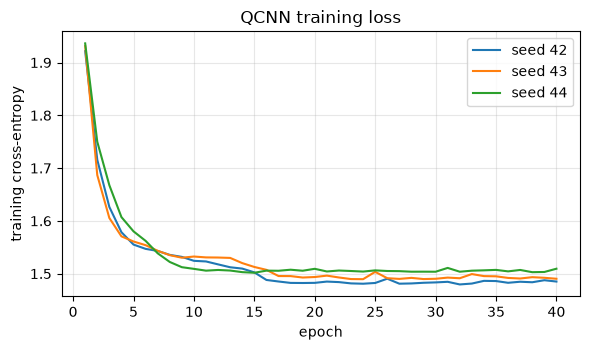

In [19]:
plt.figure(figsize=(6, 3.6))
for s in SEEDS: plt.plot(np.arange(1, len(QH[s]) + 1), QH[s], label=f"seed {s}")
plt.xlabel("epoch"); plt.ylabel("training cross-entropy"); plt.title("QCNN training loss"); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 7. Results: accuracy, per-class accuracy, confusion matrices, ROC

Re-drawing the paper's Figs. 5-8 for our data: per-class accuracy (recall) of the conventional SVM, the QSVM, the CNN and the QCNN, confusion matrices (rows = true class, normalised) and ROC curves (one-vs-rest, micro-averaged). The summary table gives mean +- std over the seeds.

In [20]:
def macro_auc(y, score):
    score = np.asarray(score, float)
    return float(np.mean([roc_auc_score(y == c, score[:, c]) for c in range(K)]))

def metrics(seed, name):
    d = SPLIT[seed]; r = RES[seed][name]; y = d["yte"]; p = r["pred"]
    rec = np.array([(p[y == c] == c).mean() for c in range(K)])
    binp = (p != 0).astype(int); biny = (y != 0).astype(int)
    return dict(acc=accuracy_score(y, p), macroF1=f1_score(y, p, average="macro"), AUC=macro_auc(y, r["score"]), normal_recall=rec[0],
                attack_detect=((binp == 1) & (biny == 1)).sum() / (biny == 1).sum(), recall=rec, t_fit=r["t_fit"], t_pred=r["t_pred"])
MODELS = list(RES[s0].keys())
rows = []
for name in MODELS:
    ms = [metrics(s, name) for s in SEEDS]
    f = lambda k: (np.mean([m[k] for m in ms]), np.std([m[k] for m in ms]))
    rows.append({"model": name, "accuracy": "%.3f +- %.3f" % f("acc"), "macro F1": "%.3f +- %.3f" % f("macroF1"), "macro AUC": "%.3f" % f("AUC")[0],
                 "normal recall": "%.3f" % f("normal_recall")[0], "attack detection rate": "%.3f" % f("attack_detect")[0],
                 "fit time (s)": "%.1f" % f("t_fit")[0], "predict (s)": "%.2f" % f("t_pred")[0]})
SUMMARY = pd.DataFrame(rows).set_index("model")
print("seeds:", SEEDS, "| test streams per seed:", len(SPLIT[s0]["yte"]))
display(SUMMARY)
print("per-class accuracy (recall), mean over seeds (the quantity plotted in the paper's Figs. 5-8):")
display(pd.DataFrame({n: np.mean([metrics(s, n)["recall"] for s in SEEDS], axis=0) for n in MODELS}, index=CLASSES).T.round(3))

seeds: [42, 43, 44] | test streams per seed: 1200


,accuracy,macro F1,macro AUC,normal recall,attack detection rate,fit time (s),predict (s)
model,,,,,,,
SVM raw fields (default),0.192 +- 0.005,0.108 +- 0.005,0.720,0.073,1.000,2.0,1.57
SVM-RBF tuned (20 fields),0.946 +- 0.006,0.944 +- 0.006,0.989,0.987,0.997,9.4,0.45
Random Forest (20 fields),0.957 +- 0.008,0.957 +- 0.009,0.997,0.998,0.997,2.3,0.60
CNN Keras (20 fields),0.931 +- 0.005,0.930 +- 0.005,0.993,0.964,0.997,33.9,1.02
SVM-RBF tuned (8 angles),0.942 +- 0.004,0.940 +- 0.005,0.986,0.987,0.996,8.2,0.34
Random Forest (8 angles),0.939 +- 0.011,0.938 +- 0.011,0.994,0.991,0.995,1.6,0.28
CNN Keras (8 angles),0.893 +- 0.015,0.889 +- 0.014,0.990,0.989,0.992,25.2,0.95
"QSVM literal (1 qubit, F x Rx)",0.289 +- 0.015,0.233 +- 0.015,0.690,0.591,0.815,3.0,0.26
QSVM ZZ (8 qubits),0.942 +- 0.007,0.941 +- 0.008,0.987,0.989,0.995,101.9,0.09


per-class accuracy (recall), mean over seeds (the quantity plotted in the paper's Figs. 5-8):


,Normal,HTTP flood,TCP flood,UDP flood,Port scan,OS fingerprint,Keylogging,Data exfiltration
SVM raw fields (default),0.073,0.996,0.384,0.018,0.000,0.002,0.007,0.053
SVM-RBF tuned (20 fields),0.987,0.996,1.000,0.996,0.651,0.982,0.956,1.000
Random Forest (20 fields),0.998,0.996,1.000,1.000,0.793,0.909,0.962,1.000
CNN Keras (20 fields),0.964,0.991,1.000,1.000,0.691,0.860,0.949,0.993
SVM-RBF tuned (8 angles),0.987,0.996,1.000,0.996,0.644,0.964,0.949,1.000
Random Forest (8 angles),0.991,0.991,1.000,1.000,0.718,0.867,0.949,0.996
CNN Keras (8 angles),0.989,0.976,1.000,1.000,0.698,0.664,0.842,0.971
"QSVM literal (1 qubit, F x Rx)",0.591,0.000,0.280,0.218,0.171,0.433,0.620,0.000
QSVM ZZ (8 qubits),0.989,0.993,0.998,0.996,0.658,0.958,0.949,1.000
QCNN (8 qubits),0.624,0.816,0.429,1.000,0.282,0.584,0.244,0.947


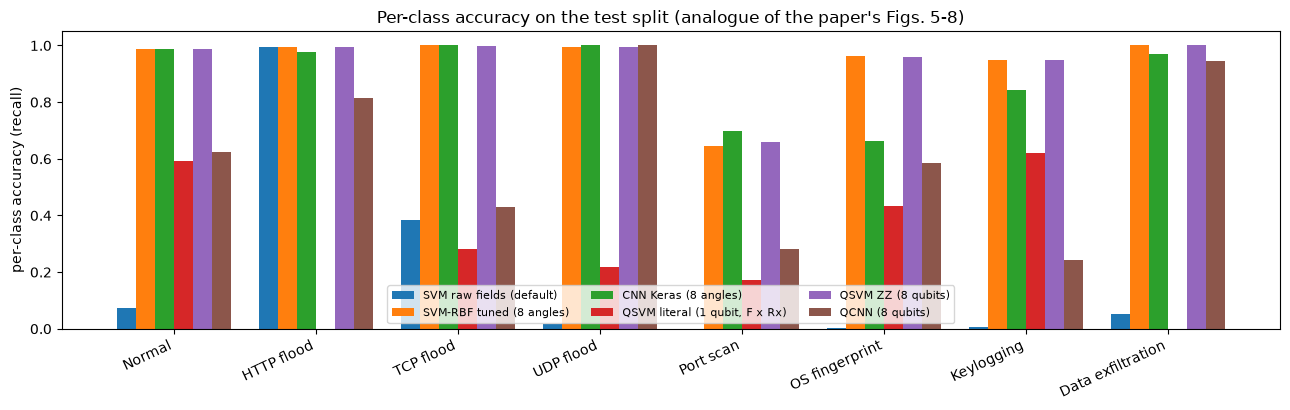

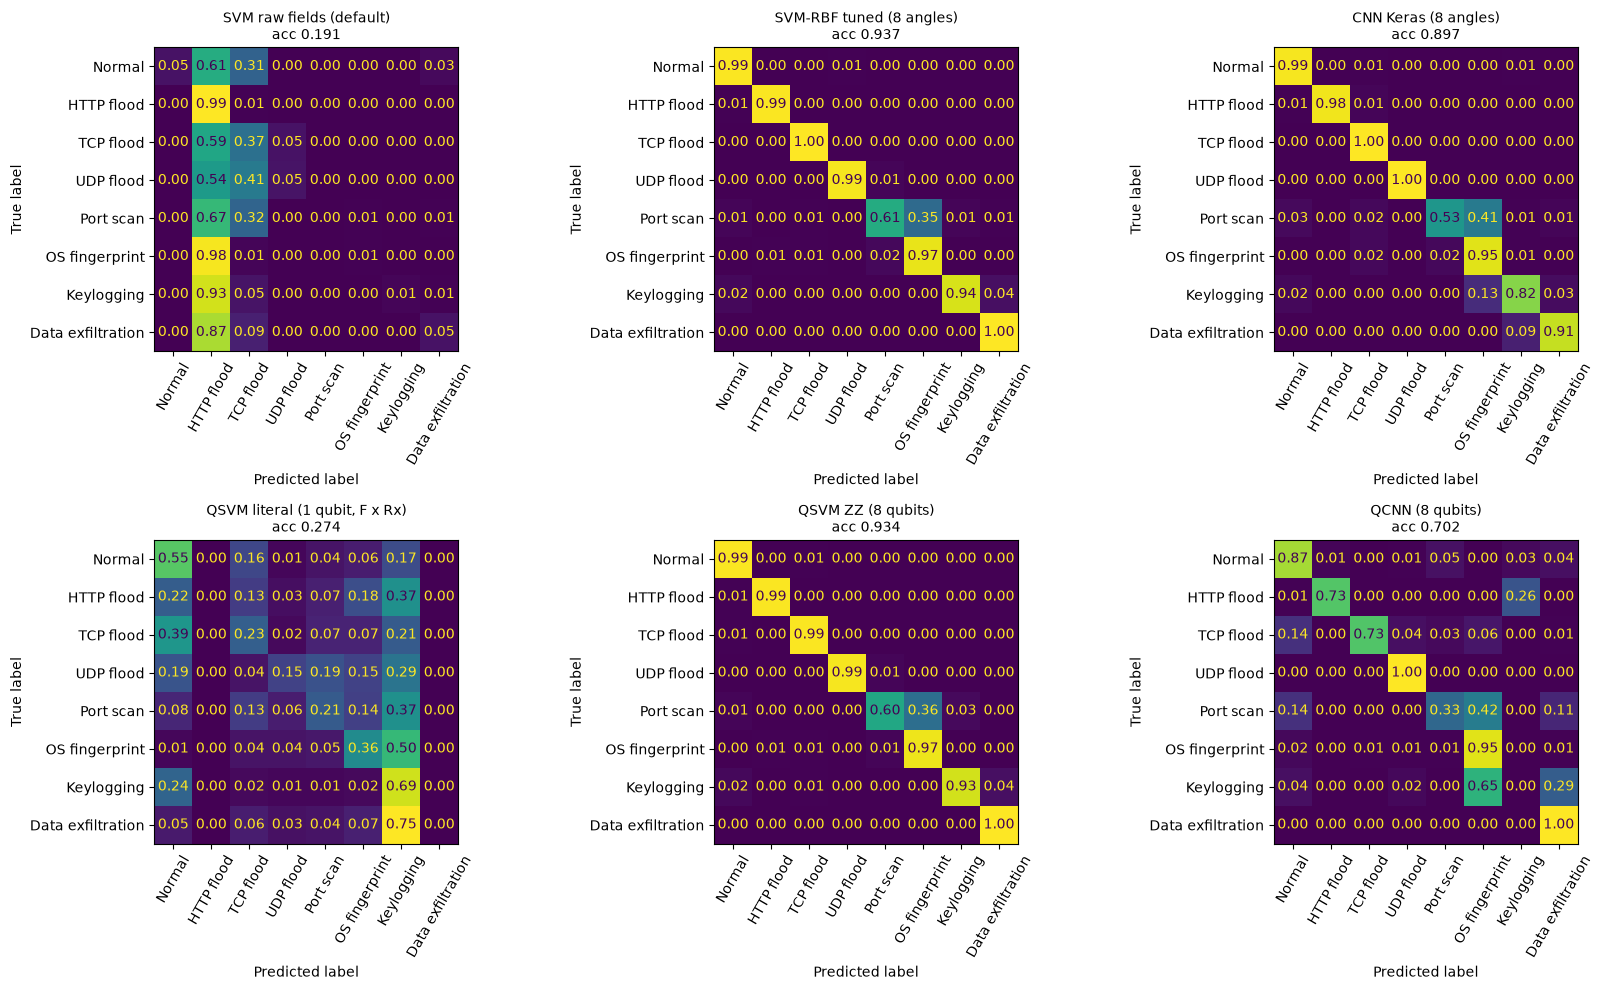

In [21]:
SHOW = ["SVM raw fields (default)", "SVM-RBF tuned (8 angles)", "CNN Keras (8 angles)", "QSVM literal (1 qubit, F x Rx)", "QSVM ZZ (8 qubits)", "QCNN (8 qubits)"]
fig, ax = plt.subplots(figsize=(13, 4.2)); w = 0.8 / len(SHOW)
for i, name in enumerate(SHOW):
    rec = np.mean([metrics(s, name)["recall"] for s in SEEDS], axis=0)
    ax.bar(np.arange(K) + (i - len(SHOW) / 2 + 0.5) * w, rec, w, label=name)
ax.set_xticks(range(K)); ax.set_xticklabels(CLASSES, rotation=25, ha="right"); ax.set_ylabel("per-class accuracy (recall)"); ax.set_ylim(0, 1.05)
ax.set_title("Per-class accuracy on the test split (analogue of the paper's Figs. 5-8)"); ax.legend(fontsize=8, ncol=3, loc="lower center"); plt.tight_layout(); plt.show()

fig, axs = plt.subplots(2, 3, figsize=(17, 10))
for ax, name in zip(axs.ravel(), SHOW):
    r = RES[s0][name]
    ConfusionMatrixDisplay(confusion_matrix(SPLIT[s0]["yte"], r["pred"], labels=range(K), normalize="true"), display_labels=CLASSES).plot(ax=ax, xticks_rotation=60, colorbar=False, values_format=".2f")
    ax.set_title(name + "\nacc %.3f" % accuracy_score(SPLIT[s0]["yte"], r["pred"]), fontsize=10)
plt.tight_layout(); plt.show()

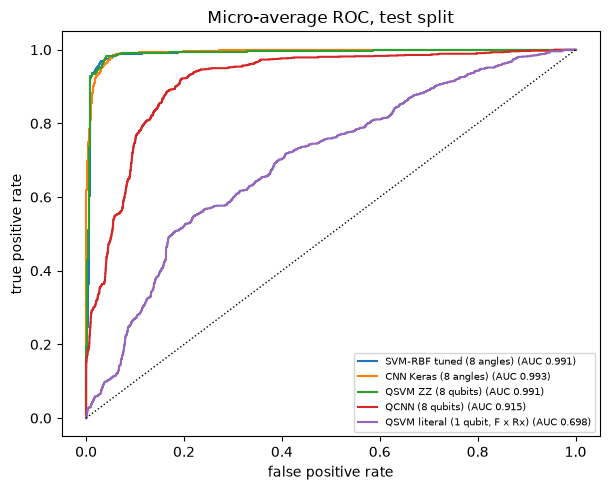

macro one-vs-rest AUC (mean over seeds): {'QSVM ZZ (8 qubits)': 0.987, 'QCNN (8 qubits)': 0.891, 'CNN Keras (8 angles)': 0.99, 'SVM-RBF tuned (8 angles)': 0.986}


In [22]:
# ROC curves (micro-average one-vs-rest) for the quantum models and their classical counterparts, seed s0
fig, ax = plt.subplots(figsize=(6.2, 5))
Yb = label_binarize(SPLIT[s0]["yte"], classes=range(K))
for name in ["SVM-RBF tuned (8 angles)", "CNN Keras (8 angles)", "QSVM ZZ (8 qubits)", "QCNN (8 qubits)", "QSVM literal (1 qubit, F x Rx)"]:
    sc_ = RES[s0][name]["score"]; fpr, tpr, _ = roc_curve(Yb.ravel(), np.asarray(sc_).ravel())
    ax.plot(fpr, tpr, label="%s (AUC %.3f)" % (name, roc_auc_score(Yb.ravel(), np.asarray(sc_).ravel())))
ax.plot([0, 1], [0, 1], "k:", lw=1); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate"); ax.set_title("Micro-average ROC, test split"); ax.legend(fontsize=7, loc="lower right"); plt.tight_layout(); plt.show()
print("macro one-vs-rest AUC (mean over seeds):", {n: round(float(np.mean([metrics(s, n)["AUC"] for s in SEEDS])), 3) for n in ["QSVM ZZ (8 qubits)", "QCNN (8 qubits)", "CNN Keras (8 angles)", "SVM-RBF tuned (8 angles)"]})

## 8. Training time against data volume (analogue of Table 4)

The paper's Table 4 lists training hours for 10^5 to 10^7 samples and claims the quantum models train about twice as fast. We cannot test 10^5 or more samples with a CPU state-vector simulator. We measure the
fit-and-predict wall-clock time of four models for a growing number of training streams (same fixed test set): RBF-SVM on the 20 fields, QSVM (ZZ, statevectors + Gram + SVC, no hyper-parameter search), Keras CNN and QCNN (a fixed number of epochs).
Important: on a classical computer a simulated quantum circuit can only be **slower** than the classical model it imitates; any speed advantage would have to come from quantum hardware that this notebook does not use.

{'n_train': 250, 'SVM': 0.06687355041503906, 'QSVM': 17.79292058944702, 'CNN': 15.302597522735596, 'QCNN': 85.87809920310974}


{'n_train': 500, 'SVM': 0.09973931312561035, 'QSVM': 17.63804841041565, 'CNN': 16.24405336380005, 'QCNN': 215.05801630020142}


{'n_train': 1000, 'SVM': 0.1839313507080078, 'QSVM': 28.034682035446167, 'CNN': 22.138922214508057, 'QCNN': 1220.9825830459595}


{'n_train': 2000, 'SVM': 0.327162504196167, 'QSVM': 32.14819288253784, 'CNN': 19.806276321411133, 'QCNN': 846.5036964416504}


,SVM,QSVM,CNN,QCNN,SVM/QSVM,CNN/QCNN
n_train,,,,,,
250,0.067,17.793,15.303,85.878,0.004,0.178
500,0.100,17.638,16.244,215.058,0.006,0.076
1000,0.184,28.035,22.139,1220.983,0.007,0.018
2000,0.327,32.148,19.806,846.504,0.010,0.023


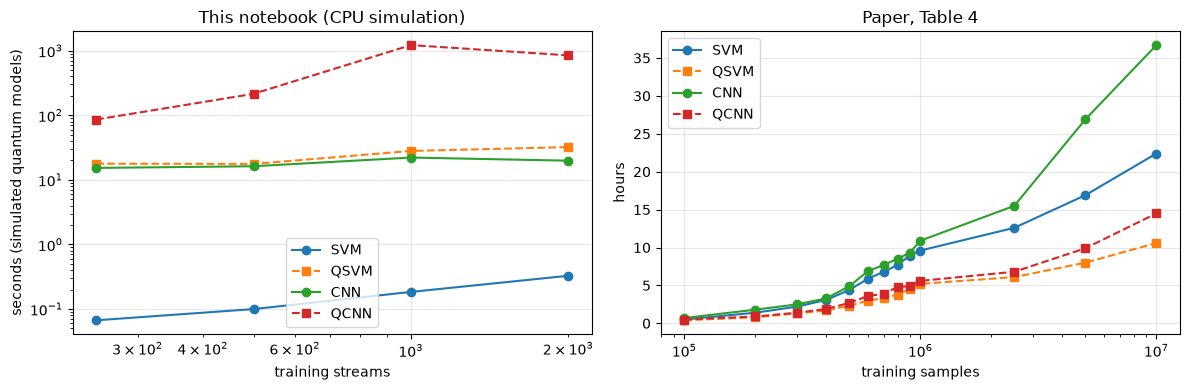

paper speed-up SVM/QSVM: 1.25 (1e5) .. 2.11 (1e7); CNN/QCNN: 1.40 .. 2.53


In [23]:
d = SPLIT[s0]; Xall, yall = d["Xtr"], d["ytr"]; bw = QZ[s0]["bw"]; C0 = QZ[s0]["C"]
TIM = []
for n in [n for n in TIMING_N if n <= len(yall)]:
    sel = train_test_split(np.arange(len(yall)), train_size=n, stratify=yall, random_state=s0)[0]
    Str_, Atr_, ytr_ = d["Str"][sel], d["Atr"][sel], yall[sel]
    t = time.time(); m = SVC(C=10, gamma="scale").fit(Str_, ytr_); m.predict(d["Ste"]); t_svm = time.time() - t
    t = time.time(); P_ = zz_states(Atr_, bw); Kt_ = fid(P_, P_); mq = SVC(kernel="precomputed", C=C0).fit(Kt_, ytr_); mq.predict(fid(zz_states(d["Ate"], bw), P_)); t_qsvm = time.time() - t
    t = time.time(); fit_cnn(Str_, ytr_, d["Ste"], s0, epochs=CNN_EPOCHS); t_cnn = time.time() - t
    t = time.time(); th_, _ = train_qcnn(Atr_, ytr_, s0, epochs=QCNN_EPOCHS); predict_qcnn(th_, d["Ate"]); t_qcnn = time.time() - t
    TIM.append(dict(n_train=n, SVM=t_svm, QSVM=t_qsvm, CNN=t_cnn, QCNN=t_qcnn)); print(TIM[-1])
TIM = pd.DataFrame(TIM).set_index("n_train")
TIM["SVM/QSVM"] = TIM["SVM"] / TIM["QSVM"]; TIM["CNN/QCNN"] = TIM["CNN"] / TIM["QCNN"]
display(TIM.round(3))

PAPER_T4 = pd.DataFrame({"n": [100e3, 200e3, 300e3, 400e3, 500e3, 600e3, 700e3, 800e3, 900e3, 1e6, 2.5e6, 5e6, 10e6],
                         "SVM": [0.5, 1.4, 2.2, 3.1, 4.4, 5.9, 6.8, 7.7, 8.9, 9.6, 12.6, 16.9, 22.4],
                         "QSVM": [0.4, 0.8, 1.3, 1.7, 2.3, 3.0, 3.3, 3.8, 4.5, 5.2, 6.1, 8.0, 10.6],
                         "CNN": [0.7, 1.8, 2.5, 3.3, 4.9, 6.9, 7.7, 8.5, 9.3, 10.9, 15.5, 26.9, 36.7],
                         "QCNN": [0.5, 0.9, 1.4, 1.9, 2.7, 3.6, 3.9, 4.8, 4.9, 5.6, 6.8, 9.9, 14.5]}).set_index("n")
PAPER_T4["SVM/QSVM"] = PAPER_T4["SVM"] / PAPER_T4["QSVM"]; PAPER_T4["CNN/QCNN"] = PAPER_T4["CNN"] / PAPER_T4["QCNN"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for c, st in zip(["SVM", "QSVM", "CNN", "QCNN"], ["o-", "s--", "o-", "s--"]):
    ax[0].plot(TIM.index, TIM[c], st, label=c); ax[1].plot(PAPER_T4.index, PAPER_T4[c], st, label=c)
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("training streams"); ax[0].set_ylabel("seconds (simulated quantum models)"); ax[0].set_title("This notebook (CPU simulation)")
ax[1].set_xscale("log"); ax[1].set_xlabel("training samples"); ax[1].set_ylabel("hours"); ax[1].set_title("Paper, Table 4")
for a in ax: a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("paper speed-up SVM/QSVM: %.2f (1e5) .. %.2f (1e7); CNN/QCNN: %.2f .. %.2f" % (PAPER_T4["SVM/QSVM"].iloc[0], PAPER_T4["SVM/QSVM"].iloc[-1], PAPER_T4["CNN/QCNN"].iloc[0], PAPER_T4["CNN/QCNN"].iloc[-1]))

## 9. Side by side with the paper

Verdict rule (repository convention): "reproduced" when the notebook is within 2 accuracy points of the paper's number or the qualitative statement holds; "not reached" when it is lower; "exceeded" when it is higher; "cannot be checked" when the data or numbers are missing.
Remember that the dataset is a stand-in, so even a matching number is a statement about Bot-IoT, not about the paper's private data.

In [24]:
def mean_of(name, key): return float(np.mean([metrics(s, name)[key] for s in SEEDS]))
def rel(v, ref, name, tol=0.01):
    # "ties" when within one accuracy point
    return f"{name} {'beats' if v > ref + tol else ('ties' if abs(v - ref) <= tol else 'is below')} the classical models"
def verdict_acc(v, target, tol=0.02):
    return "reproduced" if abs(v - target) <= tol else ("exceeded" if v > target else "not reached")

acc = {n: mean_of(n, "acc") for n in MODELS}
best_classical_8 = max(acc["SVM-RBF tuned (8 angles)"], acc["CNN Keras (8 angles)"], acc["Random Forest (8 angles)"])
rec_raw = np.mean([metrics(s, "SVM raw fields (default)")["recall"] for s in SEEDS], axis=0)
n_mid = int(((rec_raw >= 0.4) & (rec_raw <= 0.8)).sum()); n_zero = int((rec_raw < 0.1).sum())
auc_q, auc_c = mean_of("QSVM ZZ (8 qubits)", "AUC"), mean_of("QCNN (8 qubits)", "AUC")
sp_q = float(TIM["SVM/QSVM"].iloc[-1]); sp_c = float(TIM["CNN/QCNN"].iloc[-1])
rows = [
 ("C1 QSVM accuracy 98 % (Fig. 6)", "0.98", "ZZ 8 qubits %.3f ; literal 1 qubit %.3f" % (acc["QSVM ZZ (8 qubits)"], acc["QSVM literal (1 qubit, F x Rx)"]),
  "ZZ: " + verdict_acc(acc["QSVM ZZ (8 qubits)"], 0.98) + " ; literal encoding: " + verdict_acc(acc["QSVM literal (1 qubit, F x Rx)"], 0.98)),
 ("C2 conventional SVM weak (Fig. 5): most classes 0.4-0.8, one class ~0", "qualitative", "SVM raw acc %.3f ; classes with recall in [0.4,0.8]: %d of %d ; classes with recall < 0.1: %d ; tuned SVM on 20 std fields acc %.3f" % (acc["SVM raw fields (default)"], n_mid, K, n_zero, acc["SVM-RBF tuned (20 fields)"]),
  ("reproduced (qualitatively: unscaled SVM is poor, scaling/tuning removes the weakness)" if acc["SVM raw fields (default)"] < 0.7 < acc["SVM-RBF tuned (20 fields)"] else ("reproduced (SVM weak)" if acc["SVM-RBF tuned (20 fields)"] < 0.8 else "not reproduced"))),
 ("C3 QCNN normal-class accuracy 98 % (Fig. 8)", "0.98", "QCNN normal recall %.3f ; QSVM ZZ %.3f" % (mean_of("QCNN (8 qubits)", "normal_recall"), mean_of("QSVM ZZ (8 qubits)", "normal_recall")),
  verdict_acc(mean_of("QCNN (8 qubits)", "normal_recall"), 0.98)),
 ("C4 QCNN has better ROC than QSVM (Figs. 6, 8)", "QCNN > QSVM", "macro AUC QCNN %.3f vs QSVM ZZ %.3f" % (auc_c, auc_q), "reproduced" if auc_c > auc_q else "not reached (QSVM ZZ >= QCNN)"),
 ("C5 quantum models beat conventional SVM / CNN in accuracy", "QML > classical", "best quantum %.3f (QSVM ZZ %.3f, QCNN %.3f) vs best classical on the same 8 angles %.3f ; tuned SVM on 20 fields %.3f ; RF on 20 fields %.3f" % (max(acc["QSVM ZZ (8 qubits)"], acc["QCNN (8 qubits)"]), acc["QSVM ZZ (8 qubits)"], acc["QCNN (8 qubits)"], best_classical_8, acc["SVM-RBF tuned (20 fields)"], acc["Random Forest (20 fields)"]),
  rel(acc["QSVM ZZ (8 qubits)"], best_classical_8, "QSVM ZZ") + "; " + rel(acc["QCNN (8 qubits)"], best_classical_8, "QCNN") + " (best classical on the same 8 angles)" + "; Random Forest on all 20 fields is " + ("above" if acc["Random Forest (20 fields)"] > acc["QSVM ZZ (8 qubits)"] + 0.005 else "level with or below") + " the QSVM"),
 ("C6 quantum training about 2x faster (Table 4)", "SVM/QSVM 1.3-2.1, CNN/QCNN 1.4-2.5", "simulated: SVM/QSVM %.2f, CNN/QCNN %.2f at the largest N (%d streams)" % (sp_q, sp_c, TIM.index[-1]), "not reached (a simulator cannot be faster than the classical model; > 10^5 samples cannot be tested)"),
 ("C7 58-field, > 10 M record stream dataset", "10 M x 58", "Bot-IoT stand-in: %d pool streams, %d fields" % (len(df), F), "cannot be checked (private dataset)"),
]
COMP = pd.DataFrame(rows, columns=["claim", "paper", "this notebook", "verdict"]).set_index("claim")
pd.set_option("display.max_colwidth", 200)
display(COMP)

,paper,this notebook,verdict
claim,,,
C1 QSVM accuracy 98 % (Fig. 6),0.98,ZZ 8 qubits 0.942 ; literal 1 qubit 0.289,ZZ: not reached ; literal encoding: not reached
"C2 conventional SVM weak (Fig. 5): most classes 0.4-0.8, one class ~0",qualitative,"SVM raw acc 0.192 ; classes with recall in [0.4,0.8]: 0 of 8 ; classes with recall < 0.1: 6 ; tuned SVM on 20 std fields acc 0.946","reproduced (qualitatively: unscaled SVM is poor, scaling/tuning removes the weakness)"
C3 QCNN normal-class accuracy 98 % (Fig. 8),0.98,QCNN normal recall 0.624 ; QSVM ZZ 0.989,not reached
"C4 QCNN has better ROC than QSVM (Figs. 6, 8)",QCNN > QSVM,macro AUC QCNN 0.891 vs QSVM ZZ 0.987,not reached (QSVM ZZ >= QCNN)
C5 quantum models beat conventional SVM / CNN in accuracy,QML > classical,"best quantum 0.942 (QSVM ZZ 0.942, QCNN 0.616) vs best classical on the same 8 angles 0.942 ; tuned SVM on 20 fields 0.946 ; RF on 20 fields 0.957",QSVM ZZ ties the classical models; QCNN is below the classical models (best classical on the same 8 angles); Random Forest on all 20 fields is above the QSVM
C6 quantum training about 2x faster (Table 4),"SVM/QSVM 1.3-2.1, CNN/QCNN 1.4-2.5","simulated: SVM/QSVM 0.01, CNN/QCNN 0.02 at the largest N (2000 streams)",not reached (a simulator cannot be faster than the classical model; > 10^5 samples cannot be tested)
"C7 58-field, > 10 M record stream dataset",10 M x 58,"Bot-IoT stand-in: 968265 pool streams, 20 fields",cannot be checked (private dataset)


## 10. Reading the paper critically

* **No numbers to check against.** The paper reports "98 %" in the text and shows Figs. 5-8 as images without an accuracy table, a split, an optimiser, a number of epochs or the 8-or-more class names. The only table (Table 4) is about training time. We therefore compare against the 98 % claim and the qualitative statements.
* **The encoding collapses.** Appending `Rx(angle_j)` for 58 fields to one qubit is mathematically one `Rx(sum of angles)`: the model sees a single number between 0 and 2 pi. A kernel or network on that qubit cannot distinguish streams with the same angle sum, and, as our literal-encoding run shows, it cannot separate 8 traffic classes. Whatever gave the paper 98 % was therefore not this circuit as printed; either the circuits of Fig. 1 and Fig. 2 differ from the text, or the classical pre-processing (stream grouping, field choice) carried the result.
* **Simulated quantum training cannot be faster.** Table 4 compares "SVM" with "QSVM" in hours for 10^5-10^7 samples. Quantum circuits on 8-30 simulated qubits run on a classical computer cost more than the classical model. A speed-up needs error-corrected quantum hardware and a data-loading step (qRAM) that nobody has; the paper does not discuss data-loading cost. The table gives no hardware, no repetitions, and no spread.
* **Weak baselines.** The conventional SVM in Fig. 5 fails on most classes. In our run an SVM on unscaled heavy-tailed fields is exactly that bad, and a standardised, tuned SVM or a Random Forest closes the gap. The comparison "quantum vs conventional" is only meaningful against tuned baselines on identical inputs.
* **Class definition and leakage.** Splitting packets into streams removes one source of label noise, but the paper does not say whether streams from one capture session can fall into both training and test sets. With attack tools producing very regular traffic, random splits inflate accuracy.
* **Not one but several claims are "98 %".** The text says 98 % for QSVM accuracy and 98 % for the normal-class accuracy of the QCNN; these are different quantities (overall accuracy over all classes and the recall of a single class), and the abstract merges them.

## 11. Exercises

1. **Prove the collapse.** For the single-qubit circuit with `Rx(a_1) ... Rx(a_n)`, show that the state depends only on `sum a_j mod 2 pi`. Then change the encoding to alternate `Rx` and `Rz` (so the rotations no longer commute) and re-run Section 4: how does the accuracy change?
2. **Fair baselines.** Add a gradient-boosting classifier (`HistGradientBoostingClassifier`) to Section 3. Does any quantum model still beat the best classical model on the 8 angles?
3. **Bandwidth.** Add `0.1` and `2.0` to `BANDWIDTHS`. How does the kernel's test accuracy change with the angle scale, and why does a very large bandwidth hurt a fidelity kernel?
4. **Read-out.** Replace the 3-qubit read-out of the QCNN by one-vs-rest (one `Z` expectation per class on a single read-out qubit, 8 binary QCNNs). Compare accuracy and training time.
5. **Leakage.** Group Bot-IoT streams by their `stime` window (the column was dropped here) and split train/test by time instead of at random. Do the 98 %-style numbers survive?